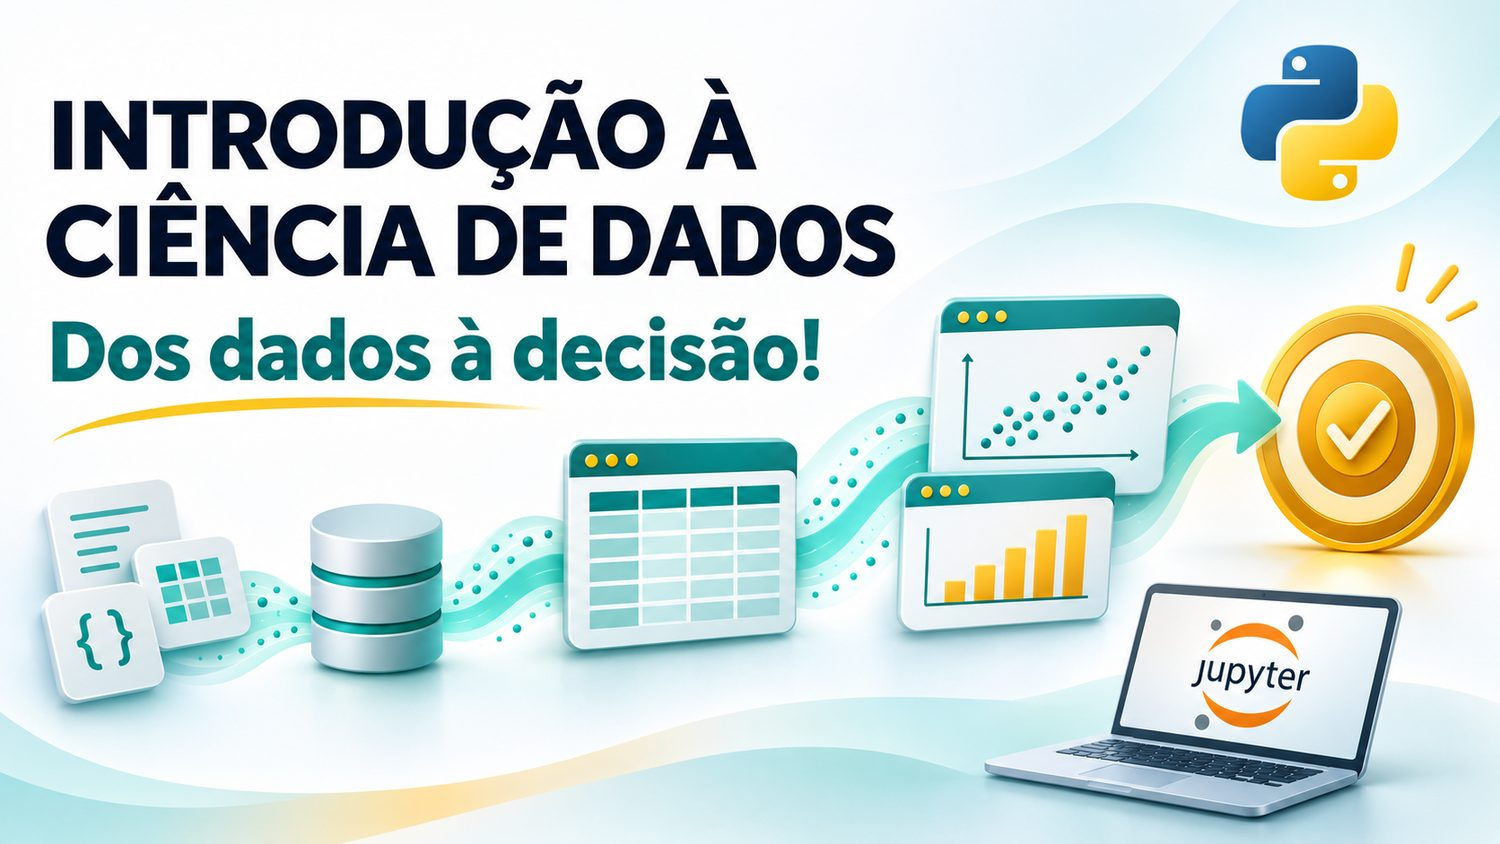

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_8_comunicar_e_usar_com_responsabilidade/04_Documentar_e_Acompanhar_um_Modelo.ipynb)

# Capítulo 4 – Documentar e acompanhar um modelo

Um modelo que funciona hoje vai ser usado durante meses ou anos, muitas vezes por pessoas que não o construíram. Daqui a um ano alguém vai perguntar para que serve, com que dados foi feito, onde falha e se ainda está a funcionar. Este capítulo trata de deixar essas respostas escritas, e de vigiar o modelo depois de entrar em uso.

> **Objetivos:** saber que perguntas um modelo em uso tem de conseguir responder; preencher uma ficha de modelo e uma ficha de dados; gerar parte da documentação a partir do código; guardar um modelo de forma reprodutível; reconhecer os tipos de deriva; vigiar as entradas, as previsões e o desempenho; decidir quando voltar a treinar ou retirar um modelo.

**Pré-requisitos:** capítulos 1 a 3, e o capítulo 6 do módulo 4 (pipelines).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_formandos(n=6000, semente=97, com_transporte=False):
    """Gera formandos de um centro de formação profissional fictício (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    zona = rng.choice(["urbana", "rural"], n, p=[0.78, 0.22])
    rural = zona == "rural"
    idade = rng.normal(34, 10, n).clip(18, 62).round()
    escolaridade = rng.choice(["básico", "secundário", "superior"], n, p=[0.3, 0.5, 0.2])
    empregado = rng.random(n) < 0.45
    distancia = np.where(rural, rng.gamma(4.0, 6.0, n), rng.gamma(2.0, 2.5, n)).clip(0.5, 70).round(1)
    computador = rng.random(n) < np.where(rural, 0.62, 0.84)
    nota_inicial = (rng.normal(58, 15, n) + 6 * (escolaridade == "superior") - 5 * (escolaridade == "básico")).clip(5, 100).round()
    transporte_irregular = rural & (rng.random(n) < 0.30)                     # não fica registado em lado nenhum
    faltas = rng.poisson(np.clip(1.0 + 0.9 * empregado + 0.035 * distancia - 0.012 * (nota_inicial - 58) + 0.6 * ~computador, 0.15, None))
    z = (-2.95 + 0.42 * faltas + 0.55 * empregado - 0.022 * (nota_inicial - 58) + 0.55 * ~computador + 0.012 * distancia + 1.7 * transporte_irregular)
    desistiu = rng.random(n) < 1 / (1 + np.exp(-z))
    tabela = pd.DataFrame({"idade": idade, "zona": zona, "escolaridade": escolaridade, "empregado": empregado, "distancia_km": distancia,
                           "tem_computador": computador, "nota_inicial": nota_inicial, "faltas_primeiro_mes": faltas, "desistiu": desistiu})
    if com_transporte:                               # só para o capítulo 5: num caso real esta coluna não existe
        tabela["transporte_irregular"] = transporte_irregular
    return tabela


formandos = gerar_formandos()
formandos.head()

,idade,zona,escolaridade,empregado,distancia_km,tem_computador,nota_inicial,faltas_primeiro_mes,desistiu
0,44.0,urbana,secundário,True,3.3,True,58.0,3,False
1,44.0,urbana,secundário,True,4.5,False,56.0,3,False
2,40.0,urbana,secundário,True,1.8,True,79.0,0,False
3,54.0,rural,básico,True,33.4,False,65.0,6,True
4,47.0,urbana,secundário,True,3.8,True,40.0,0,False


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numericas = ["idade", "distancia_km", "nota_inicial", "faltas_primeiro_mes", "empregado", "tem_computador"]
nominais = ["zona", "escolaridade"]
atributos = numericas + nominais
desenvolvimento, teste = train_test_split(formandos, test_size=0.3, random_state=0, stratify=formandos["desistiu"])
modelo = make_pipeline(ColumnTransformer([("num", StandardScaler(), numericas), ("cat", OneHotEncoder(handle_unknown="ignore"), nominais)]), LogisticRegression(max_iter=2000))
modelo.fit(desenvolvimento[atributos], desenvolvimento["desistiu"])
risco = modelo.predict_proba(teste[atributos])[:, 1]
real = teste["desistiu"].to_numpy()

## As perguntas que vão ser feitas

Um notebook responde a «como foi feito?». Quem herda um modelo faz outras perguntas.

| Quem pergunta | O que quer saber |
| --- | --- |
| Quem o usa todos os dias | Para que serve, e para que **não** serve? O que faço com o resultado? |
| Quem decide | Quão bem funciona? Onde falha? Quem responde por ele? |
| Quem o vai manter | Com que dados foi feito? Como o reproduzo? Quando foi verificado pela última vez? |
| Quem é afetado | Que dados meus usa? Posso contestar o resultado? |
| Quem audita | Foi avaliado em todos os grupos? Que riscos foram considerados? |

Há dois documentos curtos que respondem à maior parte: a **ficha do modelo** e a **ficha dos dados**. Não são relatórios; são formulários de uma ou duas páginas, que se preenchem uma vez e se atualizam quando alguma coisa muda.

## A ficha do modelo

A ideia vem dos *model cards*, propostos em 2019 por analogia com as fichas técnicas dos componentes eletrónicos e as bulas dos medicamentos.

| Secção | Perguntas a que responde |
| --- | --- |
| **Identificação** | Nome, versão, data, responsável, contacto |
| **Utilização prevista** | Que decisão apoia? Quem o usa? Em que momento? |
| **Fora do âmbito** | Para que **não** deve ser usado? |
| **Dados** | De onde vêm, de que período, quantos casos, que atributos, o que ficou de fora |
| **Modelo** | Que tipo, que preparação, como foram escolhidas as opções |
| **Desempenho** | Que métricas, medidas onde, com que margem, comparadas com quê |
| **Desempenho por grupo** | Funciona igualmente bem para todos? |
| **Limites e riscos** | Onde falha? O que pode correr mal? O que nunca foi testado? |
| **Manutenção** | Como é vigiado? Quando é revisto? O que leva a retirá-lo? |

A secção mais vezes esquecida é a segunda metade da tabela. É também a mais útil: uma ficha que só tem métricas boas é publicidade.

### Preencher os números a partir do código

A parte quantitativa deve sair do código, para não ficar desatualizada quando o modelo for treinado de novo. Reaproveitamos a função de bootstrap do capítulo 3.

In [4]:
def bootstrap(metrica, *colunas, repeticoes=1000, semente=0):
    rng = np.random.default_rng(semente)
    n = len(colunas[0])
    return np.array([metrica(*(c[p] for c in colunas)) for p in (rng.integers(0, n, n) for _ in range(repeticoes))])


def apanhados(risco, real, limiar):
    """Dos formandos que desistem, a fração que fica acima do limiar (sensibilidade)."""
    return (risco[real] >= limiar).mean()


def com_margem(metrica, *colunas, formato="{:.0%}"):
    v = bootstrap(metrica, *colunas)
    return f"{formato.format(metrica(*colunas))} ({formato.format(np.percentile(v, 2.5))} a {formato.format(np.percentile(v, 97.5))})"


limiar = float(np.quantile(risco, 0.80))                          # a equipa acompanha o quinto de maior risco
linhas = {}
for nome, filtro in [("Todos", np.ones(len(teste), dtype=bool)), ("Zona urbana", (teste["zona"] == "urbana").to_numpy()), ("Zona rural", (teste["zona"] == "rural").to_numpy()),
                     ("Menos de 30 anos", (teste["idade"] < 30).to_numpy()), ("30 anos ou mais", (teste["idade"] >= 30).to_numpy())]:
    r, y = risco[filtro], real[filtro]
    linhas[nome] = {"formandos": int(filtro.sum()), "taxa de desistência": f"{y.mean():.0%}", "AUC": com_margem(lambda a, b: roc_auc_score(b, a), r, y, formato="{:.2f}"),
                    "desistências apanhadas": com_margem(lambda a, b: apanhados(a, b, limiar), r, y), "acompanhados": f"{(r >= limiar).mean():.0%}"}
desempenho = pd.DataFrame(linhas).T
desempenho

,formandos,taxa de desistência,AUC,desistências apanhadas,acompanhados
Todos,1800,22%,0.76 (0.73 a 0.79),46% (41% a 51%),20%
Zona urbana,1390,17%,0.71 (0.68 a 0.75),29% (23% a 34%),12%
Zona rural,410,40%,0.76 (0.71 a 0.80),72% (64% a 78%),48%
Menos de 30 anos,580,25%,0.75 (0.70 a 0.79),43% (35% a 51%),22%
30 anos ou mais,1220,21%,0.77 (0.73 a 0.80),48% (42% a 54%),19%


A tabela é a secção «desempenho por grupo» da ficha. Já diz uma coisa que a linha «Todos» escondia: com o mesmo limiar, a lista apanha uma parte muito maior das desistências na zona rural do que na urbana, e acompanha uma parte muito maior dos formandos rurais. O capítulo 5 é sobre o que fazer com isto. Uma ficha de modelo serve precisamente para que estas diferenças fiquem **à vista** de quem decide.

### A ficha, preenchida

In [5]:
import sklearn

ficha = f"""
FICHA DO MODELO — Risco de desistência no fim do primeiro mês
Versão 1.0 · {pd.Timestamp('2026-01-15').strftime('%d/%m/%Y')} · Responsável: equipa de dados do centro

UTILIZAÇÃO PREVISTA
  Ordenar os formandos por risco de desistência, no fim do primeiro mês de curso, para a equipa
  de acompanhamento escolher quem contacta primeiro. Um formando assinalado recebe uma conversa
  com a tutora; nunca uma penalização.

FORA DO ÂMBITO
  Não serve para decidir admissões, bolsas ou avaliações. Não foi testado em cursos de menos
  de três meses nem em formação à distância.

DADOS
  {len(formandos)} formandos de cursos presenciais de nove meses; {len(desenvolvimento)} para treino, {len(teste)} para teste.
  Atributos: {', '.join(atributos)}.
  Alvo: desistência registada antes do fim do curso ({formandos['desistiu'].mean():.0%} dos formandos).

MODELO
  Regressão logística, com normalização das colunas numéricas e codificação das categorias.
  scikit-learn {sklearn.__version__}; semente 0; código em treinar_modelo.py.

DESEMPENHO (no teste; entre parênteses, intervalo a 95%)
  Acompanhando o quinto de maior risco, a lista apanha {desempenho.loc['Todos', 'desistências apanhadas']} das desistências.
  Escolhendo ao acaso, apanharia 20%. AUC: {desempenho.loc['Todos', 'AUC']}.

DESEMPENHO POR GRUPO
  Zona urbana: apanha {desempenho.loc['Zona urbana', 'desistências apanhadas']}; acompanha {desempenho.loc['Zona urbana', 'acompanhados']} dos formandos.
  Zona rural:  apanha {desempenho.loc['Zona rural', 'desistências apanhadas']}; acompanha {desempenho.loc['Zona rural', 'acompanhados']} dos formandos.

LIMITES E RISCOS
  Mais de metade das desistências não é assinalada. O modelo indica risco, e não se o
  acompanhamento evita a desistência. Depende muito das faltas do primeiro mês: se o registo
  de faltas mudar, deixa de ser fiável. Trata de forma diferente as duas zonas de residência.

MANUTENÇÃO
  Verificação trimestral das entradas e das previsões; verificação anual do desempenho, quando
  se conhecem as desistências. Rever se a taxa de desistência prevista e a observada diferirem
  mais de 5 pontos, ou se mudar a forma de registar faltas.
"""
print(ficha)


FICHA DO MODELO — Risco de desistência no fim do primeiro mês
Versão 1.0 · 15/01/2026 · Responsável: equipa de dados do centro

UTILIZAÇÃO PREVISTA
  Ordenar os formandos por risco de desistência, no fim do primeiro mês de curso, para a equipa
  de acompanhamento escolher quem contacta primeiro. Um formando assinalado recebe uma conversa
  com a tutora; nunca uma penalização.

FORA DO ÂMBITO
  Não serve para decidir admissões, bolsas ou avaliações. Não foi testado em cursos de menos
  de três meses nem em formação à distância.

DADOS
  6000 formandos de cursos presenciais de nove meses; 4200 para treino, 1800 para teste.
  Atributos: idade, distancia_km, nota_inicial, faltas_primeiro_mes, empregado, tem_computador, zona, escolaridade.
  Alvo: desistência registada antes do fim do curso (22% dos formandos).

MODELO
  Regressão logística, com normalização das colunas numéricas e codificação das categorias.
  scikit-learn 1.9.1; semente 0; código em treinar_modelo.py.

DESEMPENHO (no tes

Cabe numa página. Os números entre chavetas são calculados; o resto é escrito por pessoas, e é o que exige mais cuidado. Três pormenores a notar:

- a **utilização prevista** diz o que acontece a um formando assinalado. O mesmo modelo, usado para recusar inscrições, seria outro sistema, com outros riscos;
- o **fora do âmbito** nomeia usos tentadores e errados. Um modelo que existe acaba por ser usado para tudo, a menos que alguém tenha escrito que não;
- a **manutenção** tem critérios concretos. «Rever periodicamente» não obriga ninguém a nada.

## A ficha dos dados

Os problemas de um modelo vêm quase sempre dos dados. A ficha dos dados (*datasheet*) regista o que só sabe quem os recolheu.

| Secção | Perguntas |
| --- | --- |
| **Origem** | Quem recolheu, com que finalidade, com que instrumento? |
| **Período e universo** | De quando são? Quem está incluído, e quem ficou de fora? |
| **Recolha** | Cada coluna é medida, declarada ou calculada? Mudou alguma coisa ao longo do tempo? |
| **Qualidade** | Que valores faltam, e porquê? Que erros são conhecidos? |
| **Dados pessoais** | Há dados pessoais ou sensíveis? Com que base são usados? (capítulo 6) |
| **Dicionário** | O significado, a unidade e os valores possíveis de cada coluna |

O dicionário é a parte que se pode gerar e que nunca deve ser escrita só à mão: junta-se a descrição (escrita por pessoas) ao que os dados mostram.

In [6]:
descricoes = {"idade": "Idade no início do curso, em anos", "zona": "Zona de residência declarada na inscrição", "escolaridade": "Nível de ensino concluído mais alto",
              "empregado": "Se trabalha durante o curso (declarado)", "distancia_km": "Distância de casa ao centro, calculada pela morada",
              "tem_computador": "Se tem computador em casa (declarado)", "nota_inicial": "Nota no teste de diagnóstico (0 a 100)",
              "faltas_primeiro_mes": "Faltas registadas pelos formadores no primeiro mês", "desistiu": "Saída registada antes do fim do curso (alvo)"}


def dicionario(dados, descricoes):
    linhas = []
    for coluna in dados.columns:
        s = dados[coluna]
        if s.dtype == bool or not pd.api.types.is_numeric_dtype(s):
            valores = ", ".join(f"{v} ({p:.0%})" for v, p in s.value_counts(normalize=True).items())
        else:
            valores = f"de {s.min():g} a {s.max():g} (mediana {s.median():g})"
        linhas.append({"coluna": coluna, "descrição": descricoes.get(coluna, "POR DESCREVER"), "tipo": str(s.dtype), "em falta": f"{s.isna().mean():.0%}", "valores": valores})
    return pd.DataFrame(linhas).set_index("coluna")


dicionario(formandos, descricoes)

,descrição,tipo,em falta,valores
coluna,,,,
idade,"Idade no início do curso, em anos",float64,0%,de 18 a 62 (mediana 34)
zona,Zona de residência declarada na inscrição,str,0%,"urbana (77%), rural (23%)"
escolaridade,Nível de ensino concluído mais alto,str,0%,"secundário (49%), básico (31%), superior (20%)"
empregado,Se trabalha durante o curso (declarado),bool,0%,"False (54%), True (46%)"
distancia_km,"Distância de casa ao centro, calculada pela mo...",float64,0%,de 0.5 a 70 (mediana 5.5)
tem_computador,Se tem computador em casa (declarado),bool,0%,"True (79%), False (21%)"
nota_inicial,Nota no teste de diagnóstico (0 a 100),float64,0%,de 5 a 100 (mediana 58)
faltas_primeiro_mes,Faltas registadas pelos formadores no primeiro...,int64,0%,de 0 a 12 (mediana 2)
desistiu,Saída registada antes do fim do curso (alvo),bool,0%,"False (78%), True (22%)"


A palavra «declarado», em três colunas, é o género de informação que muda a leitura dos resultados. Um formando pode não dizer que trabalha. E a nota de rodapé mais importante desta ficha seria sobre o alvo: `desistiu` é uma saída **registada**; um formando que deixa de aparecer sem avisar pode ficar meses por registar.

## Reproduzir: o mínimo indispensável

Um resultado que não se consegue refazer não se consegue corrigir. O mínimo:

| O quê | Como |
| --- | --- |
| O código que treina | Num ficheiro sob controlo de versões, e não só num notebook corrido por partes |
| As versões das bibliotecas | Um `requirements.txt` com versões |
| Os sorteios | Sementes fixas na divisão dos dados e no modelo |
| Os dados | Uma cópia datada do que foi usado, ou a consulta exata que os produz |
| O modelo treinado | O **pipeline inteiro** guardado num ficheiro, com a preparação incluída |

Guardar só o modelo, sem a preparação, é um erro frequente: daqui a um ano ninguém se lembra de que as colunas eram normalizadas com a média de 2025.

In [7]:
import hashlib
import io

import joblib

memoria = io.BytesIO()                                            # num projeto real: joblib.dump(modelo, "modelo_desistencia_v1.joblib")
joblib.dump(modelo, memoria)
print(f"Pipeline guardado: {memoria.getbuffer().nbytes / 1024:.0f} kB")

memoria.seek(0)
recuperado = joblib.load(memoria)
print("As previsões do modelo recuperado são iguais às do original:", bool(np.allclose(recuperado.predict_proba(teste[atributos])[:, 1], risco)))

impressao_digital = hashlib.sha256(pd.util.hash_pandas_object(formandos, index=True).values.tobytes()).hexdigest()[:12]
print(f"Impressão digital dos dados de treino: {impressao_digital}   (se os dados mudarem, este código muda)")

Pipeline guardado: 4 kB
As previsões do modelo recuperado são iguais às do original: True
Impressão digital dos dados de treino: 998f624a6809   (se os dados mudarem, este código muda)


O ficheiro guardado contém a preparação e o modelo: recebe a tabela original e devolve o risco. A impressão digital dos dados, registada na ficha, permite confirmar mais tarde que se está a olhar para os mesmos dados.

Dois avisos sobre ficheiros de modelos: só funcionam com versões compatíveis das bibliotecas (daí o `requirements.txt`), e **nunca se deve abrir um ficheiro destes vindo de uma fonte em que não se confia**, porque pode executar código ao ser carregado.

## Depois de entrar em uso: o mundo muda

Um modelo aprende a relação entre atributos e alvo **nos dados de um certo período**. Quando o mundo muda, o modelo não sabe. Chama-se a isto **deriva** (*drift*).

| Tipo | O que muda | Exemplo no centro |
| --- | --- | --- |
| **Deriva das entradas** | A distribuição dos atributos | Passam a inscrever-se formandos mais velhos; abre um polo numa zona rural |
| **Deriva da relação** | O que os atributos significam para o alvo | O centro passa a pagar o passe: a distância deixa de pesar |
| **Mudança na medição** | A forma de registar um atributo ou o alvo | As faltas passam a ser registadas por uma aplicação, e não pelo formador |

O terceiro tipo é o mais traiçoeiro: nada mudou na realidade, e o modelo passa a receber números que significam outra coisa.

Simulamos esse caso. No ano seguinte, o centro passa a ter um dia por semana de aulas à distância, em que **as faltas não são registadas**. Os formandos e as desistências são os mesmos; só o número de faltas registadas baixa.

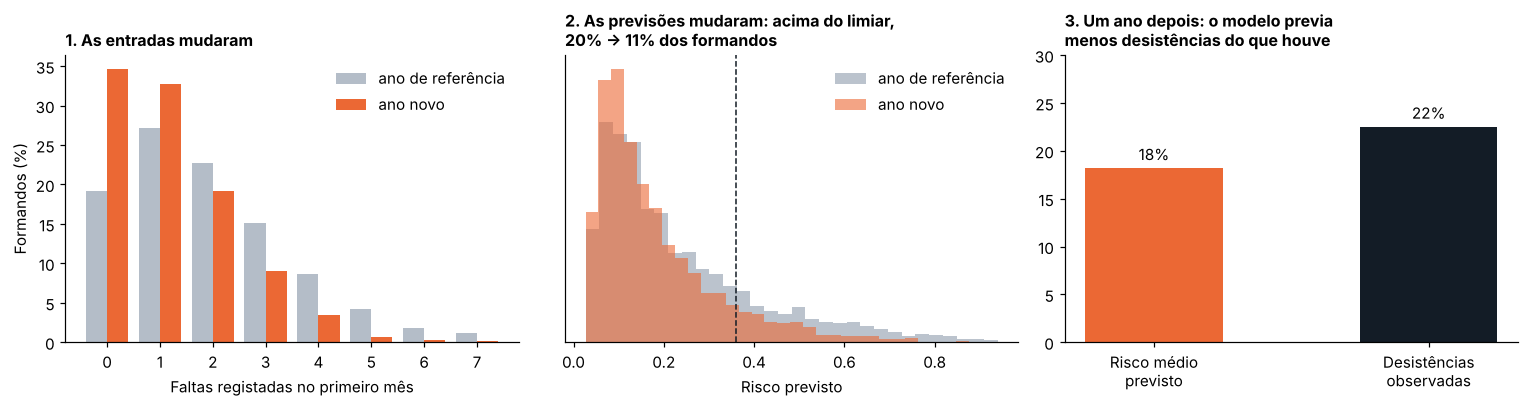

In [8]:
rng = np.random.default_rng(5)
ano_novo = teste.copy()
ano_novo["faltas_primeiro_mes"] = rng.binomial(teste["faltas_primeiro_mes"], 0.6)       # cada falta só fica registada com probabilidade 0,6
risco_novo = modelo.predict_proba(ano_novo[atributos])[:, 1]

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8))
maximo = 7
for dados, cor, nome, desvio in [(teste, CINZA, "ano de referência", -0.2), (ano_novo, LARANJA, "ano novo", 0.2)]:
    contagem = dados["faltas_primeiro_mes"].clip(upper=maximo).value_counts(normalize=True).reindex(range(maximo + 1), fill_value=0)
    eixos[0].bar(contagem.index + desvio, contagem * 100, 0.4, color=cor, label=nome)
eixos[0].set_xlabel("Faltas registadas no primeiro mês")
eixos[0].set_ylabel("Formandos (%)")
eixos[0].set_title("1. As entradas mudaram", fontsize=10.5)
eixos[0].legend(frameon=False)
eixos[1].hist(risco, bins=30, color=CINZA, alpha=0.9, label="ano de referência")
eixos[1].hist(risco_novo, bins=30, color=LARANJA, alpha=0.6, label="ano novo")
eixos[1].axvline(limiar, color=TINTA, ls="--", lw=1)
eixos[1].set_xlabel("Risco previsto")
eixos[1].set_yticks([])
eixos[1].set_title(f"2. As previsões mudaram: acima do limiar,\n{(risco >= limiar).mean():.0%} → {(risco_novo >= limiar).mean():.0%} dos formandos", fontsize=10.5)
eixos[1].legend(frameon=False)
barras = eixos[2].bar(["Risco médio\nprevisto", "Desistências\nobservadas"], [risco_novo.mean() * 100, real.mean() * 100], color=[LARANJA, TINTA], width=0.5)
eixos[2].bar_label(barras, fmt="%.0f%%", padding=3)
eixos[2].set_ylim(0, 30)
eixos[2].set_title("3. Um ano depois: o modelo previa\nmenos desistências do que houve", fontsize=10.5)
plt.tight_layout()
plt.show()

Os três painéis são os três níveis de vigilância, do mais rápido ao mais lento.

1. **As entradas.** Vê-se logo no primeiro mês: há mais formandos com zero faltas e menos com muitas. Não é preciso esperar pelo resultado de ninguém.
2. **As previsões.** Também imediatas: o modelo assinala muito menos formandos do que os 20% para que a equipa está dimensionada.
3. **O desempenho.** Só se mede quando se conhecem as desistências, meses depois. Nessa altura, o risco médio previsto ficou bem abaixo da taxa observada: o modelo deixou de estar calibrado.

O alvo de um modelo chega quase sempre **com atraso**. Por isso se vigiam as entradas e as previsões: são o alarme que toca a tempo.

### Um painel de vigilância simples

In [9]:
def vigiar(referencia, atual, colunas):
    """Compara as médias de cada coluna numérica, em desvios padrão da referência."""
    linhas = []
    for coluna in colunas:
        a, b = referencia[coluna].astype(float), atual[coluna].astype(float)
        desvio = (b.mean() - a.mean()) / a.std()
        linhas.append({"atributo": coluna, "referência": a.mean(), "atual": b.mean(), "diferença (em desvios padrão)": desvio, "alerta": "VERIFICAR" if abs(desvio) > 0.2 else ""})
    return pd.DataFrame(linhas).set_index("atributo")


painel = vigiar(teste, ano_novo, numericas)
painel.loc["risco previsto (média)"] = [risco.mean(), risco_novo.mean(), (risco_novo.mean() - risco.mean()) / risco.std(), "VERIFICAR" if abs(risco_novo.mean() - risco.mean()) / risco.std() > 0.2 else ""]
painel.round(2)

,referência,atual,diferença (em desvios padrão),alerta
atributo,,,,
idade,34.38,34.38,0.00,
distancia_km,9.12,9.12,0.00,
nota_inicial,57.31,57.31,0.00,
faltas_primeiro_mes,1.94,1.17,-0.47,VERIFICAR
empregado,0.47,0.47,0.00,
tem_computador,0.77,0.77,0.00,
risco previsto (média),0.23,0.18,-0.30,VERIFICAR


Uma tabela destas, corrida todos os meses, teria apanhado o problema na primeira semana. O limiar de 0,2 desvios padrão é uma convenção: o que interessa é haver um critério escrito e alguém responsável por olhar.

Um alerta não diz o que fazer; diz que é preciso ir ver. Aqui, a investigação levaria à mudança no registo de faltas, e a decisão seria uma de três:

| Opção | Quando |
| --- | --- |
| **Corrigir a entrada** | A mudança é na medição, e é possível reconstituir o valor antigo |
| **Voltar a treinar** | Há dados suficientes do novo regime, com o alvo conhecido |
| **Suspender o modelo** | Nenhuma das anteriores é possível; volta-se à regra manual até haver dados |

Suspender é uma opção legítima, e convém que esteja prevista. Um modelo que continua em uso depois de deixar de funcionar é pior do que não ter modelo, porque as pessoas confiam nele.

## O ciclo de vida, em resumo

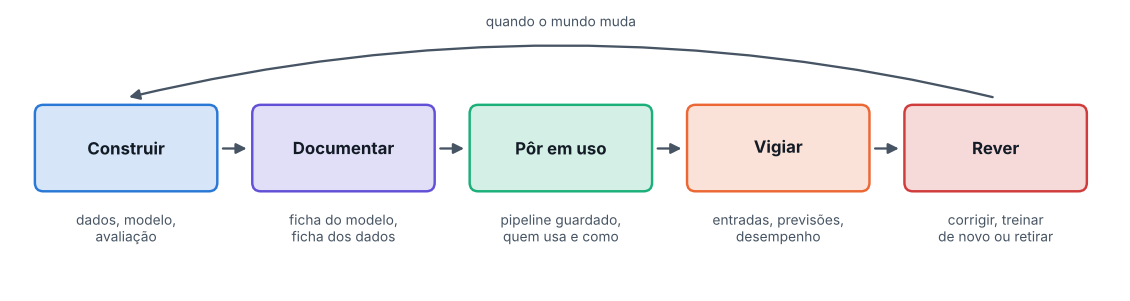

In [10]:
fig, ax = tela(13, 3.6, tamanho=(13, 3.3))
etapas = [("Construir", "dados, modelo,\navaliação", AZUL), ("Documentar", "ficha do modelo,\nficha dos dados", VIOLETA), ("Pôr em uso", "pipeline guardado,\nquem usa e como", VERDE),
          ("Vigiar", "entradas, previsões,\ndesempenho", LARANJA), ("Rever", "corrigir, treinar\nde novo ou retirar", MAU)]
for i, (titulo, detalhe, cor) in enumerate(etapas):
    caixa(ax, 0.3 + i * 2.55, 1.55, 2.1, 0.95, titulo, cor=cor, tamanho=11, negrito=True)
    ax.text(1.35 + i * 2.55, 1.3, detalhe, ha="center", va="top", fontsize=9, color="#465463")
    if i < len(etapas) - 1:
        seta(ax, (2.45 + i * 2.55, 2.02), (2.8 + i * 2.55, 2.02))
seta(ax, (11.55, 2.6), (1.35, 2.6), connectionstyle="arc3,rad=0.12")
ax.text(6.45, 3.42, "quando o mundo muda", ha="center", fontsize=9, color="#465463")
ax.set_ylim(0.4, 3.6)
plt.show()

Construir o modelo é a primeira de cinco etapas. As outras quatro raramente aparecem nos cursos, e ocupam a maior parte da vida de um modelo que serve para alguma coisa.

## Exercícios

### `Exercício 1` – O que falta nesta ficha?

Uma ficha de modelo diz: «Modelo de previsão de incumprimento de pagamento de propinas. Gradient boosting com 500 árvores. Exatidão de 94% no teste. Treinado com dados de 2022 a 2024.» Indica cinco perguntas a que esta ficha não responde.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. **Para que é usado?** O que acontece a um formando assinalado: um lembrete, um plano de pagamentos, ou a suspensão da inscrição?
2. **94% comparado com quê?** Se 6% dos formandos não pagam, dizer sempre «paga» também acerta 94%.
3. **Que erros comete, e quantos de cada tipo?** A exatidão não distingue um falso alarme de um caso não detetado.
4. **Funciona igualmente bem em todos os grupos** (idade, situação de emprego, zona)?
5. **Com que margem?** Quantos casos tinha o teste?
6. **Quem responde por ele, como é vigiado, e o que leva a retirá-lo?**
7. **Que dados pessoais usa, e os formandos sabem?**

Qualquer cinco destas servem. A ficha descreve o **modelo** e não diz nada sobre o seu **uso**, que é onde estão os riscos.

</details>

### `Exercício 2` – Deriva das entradas

Simula outro tipo de mudança: o centro abre um polo numa zona rural e a proporção de formandos rurais passa de 22% para 50%. Constrói o «ano novo» reamostrando o teste com essa proporção. O painel de vigilância dá alerta? O que acontece à percentagem de formandos acima do limiar, e à sensibilidade?

In [11]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
rurais, urbanos = teste[teste["zona"] == "rural"], teste[teste["zona"] == "urbana"]
polo = pd.concat([rurais.sample(900, replace=True, random_state=0), urbanos.sample(900, random_state=0)])
risco_polo, real_polo = modelo.predict_proba(polo[atributos])[:, 1], polo["desistiu"].to_numpy()
print(vigiar(teste, polo, numericas).round(2)[["diferença (em desvios padrão)", "alerta"]])
print(f"Acima do limiar: {(risco >= limiar).mean():.0%} → {(risco_polo >= limiar).mean():.0%} | sensibilidade: {apanhados(risco, real, limiar):.0%} → {apanhados(risco_polo, real_polo, limiar):.0%}")
print(f"Risco médio previsto {risco_polo.mean():.0%} | desistências observadas {real_polo.mean():.0%}")
```

O painel dá alerta na distância (os formandos rurais moram mais longe) e no risco previsto. O modelo passa a assinalar muito mais formandos do que a equipa consegue acompanhar. Mas o modelo **não ficou errado**: o risco previsto continua próximo do observado, e a sensibilidade até sobe. Mudou a população, e não a relação. A resposta aqui não é voltar a treinar: é rever a capacidade da equipa ou o limiar. Distinguir os dois casos é o trabalho de quem recebe o alerta.

</details>

### `Exercício 3` – O dicionário como teste

Usa a função `dicionario` no «ano novo» das faltas não registadas (`ano_novo`) e compara a linha de `faltas_primeiro_mes` com a dos dados originais. Escreve uma verificação automática (um `assert`, ou uma função que devolva avisos) que teria detetado a mudança.

In [12]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
print(dicionario(teste, descricoes).loc["faltas_primeiro_mes", "valores"], "|", dicionario(ano_novo, descricoes).loc["faltas_primeiro_mes", "valores"])


def verificar_entradas(dados, referencia, tolerancia=0.25):
    avisos = []
    for coluna in numericas:
        esperado, observado = referencia[coluna].astype(float).mean(), dados[coluna].astype(float).mean()
        if abs(observado - esperado) > tolerancia * referencia[coluna].astype(float).std():
            avisos.append(f"{coluna}: média {observado:.2f}, esperava-se cerca de {esperado:.2f}")
    return avisos


print(verificar_entradas(ano_novo, teste))
```

A mediana e o máximo das faltas baixam. A função compara cada média com a de referência e devolve a lista de colunas suspeitas; num sistema em uso, correria antes de cada previsão e bloquearia a lista (ou avisaria alguém) quando a lista de avisos não estivesse vazia. Verificar as entradas antes de prever é a forma mais barata de vigilância.

</details>

### `Exercício 4` – Critérios de revisão

Escreve três critérios concretos (com números) que levariam a rever o modelo de desistência, e para cada um diz com que frequência seria verificado e por quem.

<details>
<summary><b>Ver uma solução possível</b></summary>

| Critério | Frequência | Quem |
| --- | --- | --- |
| A média de alguma entrada afasta-se mais de 0,25 desvios padrão da referência | Mensal, automático | Equipa de dados |
| A percentagem de formandos acima do limiar sai do intervalo de 15% a 25% | Mensal, automático | Equipa de dados, com aviso à coordenadora |
| A taxa de desistência observada difere mais de 5 pontos do risco médio previsto | Anual, quando fecham os cursos | Equipa de dados e direção |
| A lista apanha menos de um terço das desistências (era quase metade) | Anual | Equipa de dados e direção |
| Muda a forma de registar faltas, ou os critérios de admissão | Sempre que aconteça | Quem decide a mudança avisa a equipa de dados |

O último é o mais importante e o único que não se automatiza: depende de as pessoas que mudam os processos saberem que existe um modelo que depende deles. É mais uma razão para a ficha do modelo existir e ser conhecida.

</details>

## Verifica o que aprendeste

- [ ] Sei que perguntas um modelo em uso tem de conseguir responder.
- [ ] Sei preencher uma ficha de modelo, incluindo o que fica fora do âmbito.
- [ ] Sei gerar a parte quantitativa da ficha a partir do código.
- [ ] Sei o que entra numa ficha de dados e num dicionário de dados.
- [ ] Sei guardar um pipeline completo e porque não basta guardar o modelo.
- [ ] Sei distinguir deriva das entradas, deriva da relação e mudança na medição.
- [ ] Sei porque se vigiam as entradas e as previsões, e não só o desempenho.
- [ ] Sei que suspender um modelo é uma opção.

## Leitura recomendada

- https://arxiv.org/abs/1810.03993
- https://arxiv.org/abs/1803.09010
- https://scikit-learn.org/stable/model_persistence.html
- https://en.wikipedia.org/wiki/Concept_drift